Training data: (60000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8206 - loss: 0.5051 - val_accuracy: 0.8517 - val_loss: 0.4061
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.8795 - loss: 0.3346 - val_accuracy: 0.8810 - val_loss: 0.3266
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.8952 - loss: 0.2878 - val_accuracy: 0.8867 - val_loss: 0.3131
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.9061 - loss: 0.2571 - val_accuracy: 0.8992 - val_loss: 0.2791
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.9139 - loss: 0.2330 - val_accuracy: 0.9038 - val_loss: 0.2625
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9084 - loss: 0.2469
Test Accuracy: 90.84 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


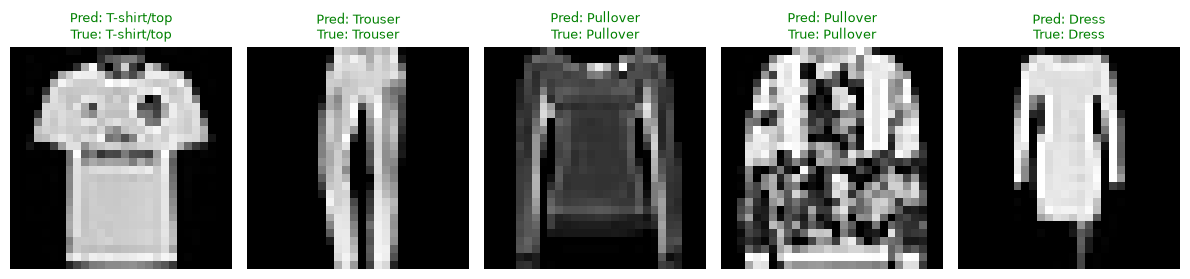

In [1]:

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

# 1. Load Fashion-MNIST CSV files
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

'''
# Load Fashion-MNIST dataset using CSV files
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

y_train = train_df['label'].values
X_train = train_df.drop(columns=['label']).values
y_test = test_df['label'].values
X_test = test_df.drop(columns=['label']).values

# Alternative: Load Fashion-MNIST directly from TensorFlow
# (X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
'''

# Separate labels and pixel values
y_train = train_df['label'].values
X_train = train_df.drop(columns=['label']).values

y_test = test_df['label'].values
X_test = test_df.drop(columns=['label']).values

# 2. Normalize pixel values and reshape into images
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Fashion-MNIST class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# 3. Build CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten and classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# 4. Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 5. Train the CNN
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# 6. Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", round(test_acc * 100, 2), "%")

# 7. Predict labels for five test images
five_images = X_test[:5]
true_labels = y_test[:5]

predictions = model.predict(five_images)
predicted_labels = np.argmax(predictions, axis=1)

# Display images with actual and predicted labels
plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(five_images[i].squeeze(), cmap='gray')

    actual = class_names[true_labels[i]]
    predicted = class_names[predicted_labels[i]]

    color = 'green' if true_labels[i] == predicted_labels[i] else 'red'

    plt.title(
        "Pred: " + predicted + "\nTrue: " + actual,
        color=color,
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()
